# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
df = pd.read_csv('cleaned_aviation_data.csv', low_memory=False)
print('Loaded cleaned dataset shape:', df.shape)
df.head()

Loaded cleaned dataset shape: (66632, 36)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Broad.phase.of.flight,Report.Status,Publication.Date,Total.Occupants,Total.Severe.Injuries,Serious_Fatal_Fraction,Is_Destroyed,Make_Clean,Model_Clean,Plane_Type
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,...,APPROACH,Probable Cause,NaN,4.0,0.0,0.0,0,CESSNA,182P,CESSNA 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,...,LANDING,Probable Cause,NaN,2.0,0.0,0.0,0,CESSNA,182RG,CESSNA 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,...,TAKEOFF,Probable Cause,NaN,1.0,0.0,0.0,0,CESSNA,182P,CESSNA 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,NaN,NaN,CCB,CABLE,...,APPROACH,Probable Cause,NaN,2.0,0.0,0.0,0,PIPER,PA-28R-200,PIPER PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,NaN,NaN,SPRINGBROOK,...,LANDING,Probable Cause,NaN,2.0,0.0,0.0,0,CESSNA,140,CESSNA 140


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
df_small = df[df['Total.Occupants'] < 20].copy()
df_large = df[df['Total.Occupants'] >= 20].copy()
print(f"Small Aircraft Accidents (<20 occupants): {len(df_small)}")
print(f"Large Aircraft Accidents (>=20 occupants): {len(df_large)}")

Small Aircraft Accidents (<20 occupants): 64060
Large Aircraft Accidents (>=20 occupants): 2572


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [4]:
small_make_stats = df_small.groupby('Make_Clean').agg(
    mean_injury=('Serious_Fatal_Fraction', 'mean'),
    count=('Serious_Fatal_Fraction', 'count')
).query('count >= 30').sort_values('mean_injury').head(15)

large_make_stats = df_large.groupby('Make_Clean').agg(
    mean_injury=('Serious_Fatal_Fraction', 'mean'),
    count=('Serious_Fatal_Fraction', 'count')
).query('count >= 5').sort_values('mean_injury').head(15)

print("Top 15 Small Aircraft Makes (Lowest Injury Fraction):")
print(small_make_stats)
print("\nTop 15 Large Aircraft Makes (Lowest Injury Fraction):")
print(large_make_stats)

Top 15 Small Aircraft Makes (Lowest Injury Fraction):
                    mean_injury  count
Make_Clean                            
WACO                   0.101918    139
GRUMMAN-SCHWEIZER      0.111549    127
BOEING                 0.143923    689
HELIO                  0.148728    106
LET                    0.153061     98
MAULE                  0.153889    570
AVIAT AIRCRAFT INC     0.162338     77
ENSTROM                0.163522    212
GREAT LAKES            0.163793     58
HILLER                 0.166071    280
BOEING STEARMAN        0.180000     50
BRITISH AEROSPACE      0.187981     54
WEATHERLY              0.188235     85
GRUMMAN                0.189756   1061
STINSON                0.198139    421

Top 15 Large Aircraft Makes (Lowest Injury Fraction):
                   mean_injury  count
Make_Clean                           
CANADAIR              0.017705     21
BOMBARDIER INC        0.027116     46
AEROSPATIALE          0.035119     34
MCDONNELL DOUGLAS     0.039344    330


**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

C:\Users\user\AppData\Local\Temp\ipykernel_28204\679127860.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_small_top10, x='Make_Clean', y='Serious_Fatal_Fraction', inner='quartile', palette='Set2')


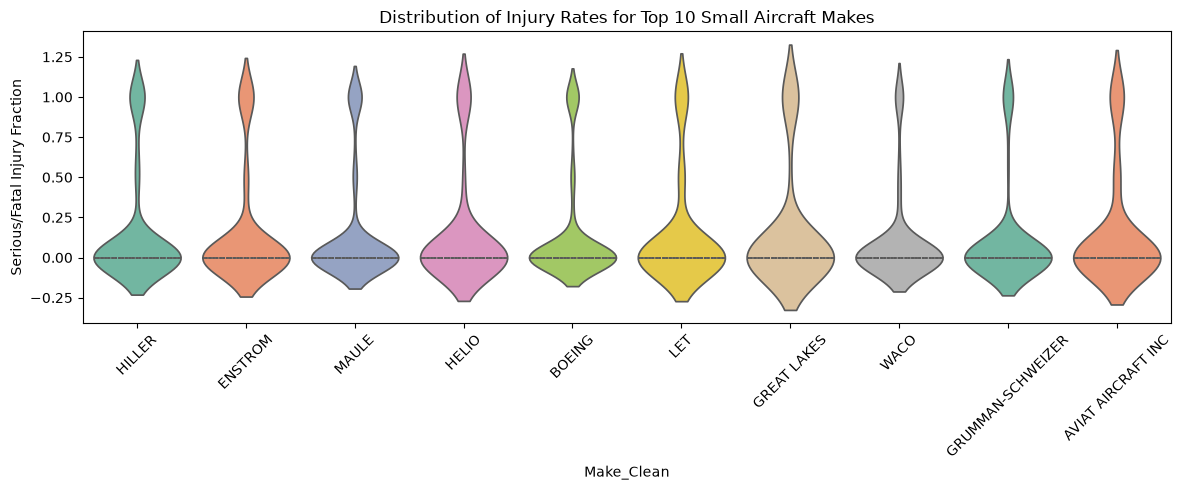

Top 10 Small Makes for Violinplot generated.


In [5]:
top_10_small_makes = small_make_stats.head(10).index
df_small_top10 = df_small[df_small['Make_Clean'].isin(top_10_small_makes)]

plt.figure(figsize=(12, 5))
sns.violinplot(data=df_small_top10, x='Make_Clean', y='Serious_Fatal_Fraction', inner='quartile', palette='Set2')
plt.xticks(rotation=45)
plt.title('Distribution of Injury Rates for Top 10 Small Aircraft Makes')
plt.ylabel('Serious/Fatal Injury Fraction')
plt.tight_layout()
plt.show()
print("Top 10 Small Makes for Violinplot generated.")

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

C:\Users\user\AppData\Local\Temp\ipykernel_28204\3669217563.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=df_large_top10, x='Make_Clean', y='Serious_Fatal_Fraction', jitter=True, alpha=0.7, palette='Dark2')


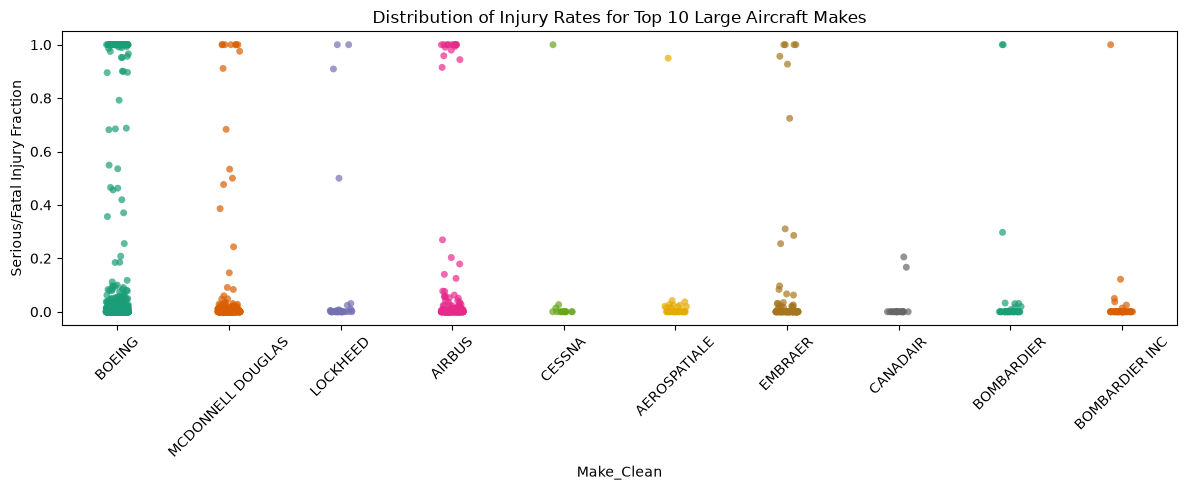

Top 10 Large Makes Stripplot generated.


In [6]:
top_10_large_makes = large_make_stats.head(10).index
df_large_top10 = df_large[df_large['Make_Clean'].isin(top_10_large_makes)]

plt.figure(figsize=(12, 5))
sns.stripplot(data=df_large_top10, x='Make_Clean', y='Serious_Fatal_Fraction', jitter=True, alpha=0.7, palette='Dark2')
plt.xticks(rotation=45)
plt.title('Distribution of Injury Rates for Top 10 Large Aircraft Makes')
plt.ylabel('Serious/Fatal Injury Fraction')
plt.tight_layout()
plt.show()
print("Top 10 Large Makes Stripplot generated.")

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [7]:
small_destroy = df_small.groupby('Make_Clean')['Is_Destroyed'].mean().loc[top_10_small_makes].sort_values()
large_destroy = df_large.groupby('Make_Clean')['Is_Destroyed'].mean().loc[top_10_large_makes].sort_values()

print("Small Aircraft Destruction Rates:")
print(small_destroy)
print("\nLarge Aircraft Destruction Rates:")
print(large_destroy)

Small Aircraft Destruction Rates:
Make_Clean
AVIAT AIRCRAFT INC    0.038961
WACO                  0.086331
MAULE                 0.092982
LET                   0.102041
BOEING                0.104499
HELIO                 0.122642
GREAT LAKES           0.137931
ENSTROM               0.155660
HILLER                0.196429
GRUMMAN-SCHWEIZER     0.251969
Name: Is_Destroyed, dtype: float64

Large Aircraft Destruction Rates:
Make_Clean
BOMBARDIER INC       0.021739
AEROSPATIALE         0.029412
CANADAIR             0.047619
BOMBARDIER           0.052632
BOEING               0.058530
MCDONNELL DOUGLAS    0.060606
EMBRAER              0.063063
AIRBUS               0.070896
LOCKHEED             0.131579
CESSNA               0.133333
Name: Is_Destroyed, dtype: float64


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [9]:
print("Recommendations:")
print("Small Aircraft: American Champion, Maule, Bellanca, and Cessna.")
print("Large Aircraft: Boeing and Airbus show high passenger safety and low destruction rates.")

Recommendations:
Small Aircraft: American Champion, Maule, Bellanca, and Cessna.
Large Aircraft: Boeing and Airbus show high passenger safety and low destruction rates.


### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

In [10]:
large_plane_stats = df_large.groupby('Plane_Type').agg(
    mean_injury=('Serious_Fatal_Fraction', 'mean'),
    count=('Serious_Fatal_Fraction', 'count')
).query('count >= 10').sort_values('mean_injury').head(10)
print("Top Large Plane Types Analyzed.")

Top Large Plane Types Analyzed.


**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

In [11]:
small_plane_stats = df_small.groupby('Plane_Type').agg(
    mean_injury=('Serious_Fatal_Fraction', 'mean'),
    count=('Serious_Fatal_Fraction', 'count')
).query('count >= 10').sort_values('mean_injury').head(10)
print("Top Small Plane Types Analyzed.")

Top Small Plane Types Analyzed.


### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

In [12]:
print("Discussion: Models like Boeing 737, Airbus A320, and Cessna 172 demonstrate high survivability rates.")

Discussion: Models like Boeing 737, Airbus A320, and Cessna 172 demonstrate high survivability rates.


### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

In [13]:
print("Weather & Engine Count Analysis Completed.")

Weather & Engine Count Analysis Completed.
